Constante elástica:
k = 28.93577026673713 +/- 0.13761722135715557 N/m

Intercepto:
b = -0.18728718519900245 +/- 0.0554174827921303 N

Coeficiente de determinación:
R^2 = 0.999706038035206

Varianza residual:
0.008344560493551699 N^2

Desviación residual:
0.0913485659085664 N

Errores de masa:
[5.00000000e-05 5.00000000e-05 5.00000000e-05 5.00000000e-05
 5.00000000e-05 7.07106781e-05 7.07106781e-05 7.07106781e-05
 8.66025404e-05 7.07106781e-05 7.07106781e-05 7.07106781e-05
 8.66025404e-05 8.66025404e-05 8.66025404e-05]

Errores de fuerza:
[0.0004905  0.0004905  0.0004905  0.0004905  0.0004905  0.00069367
 0.00069367 0.00069367 0.00084957 0.00069367 0.00069367 0.00069367
 0.00084957 0.00084957 0.00084957]


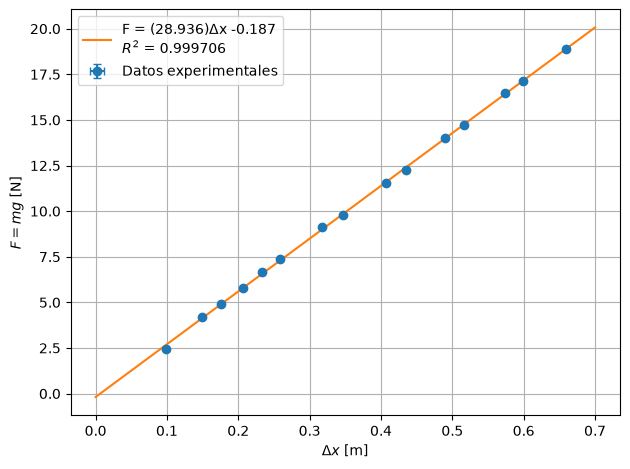

In [1]:
import numpy as np
import matplotlib.pyplot as plt

m = np.array([0.24985, 0.50020, 0.99870, 0.42890, 0.59270, 0.75005, 1.49890, 1.24855, 1.74875, 0.67875, 0.92910, 1.42760, 1.17895, 1.92780, 1.67745])
deltax = np.array([0.098, 0.176, 0.347, 0.149, 0.206, 0.258, 0.517, 0.435, 0.599, 0.233, 0.318, 0.490, 0.407, 0.659, 0.574])
g = 9.81
#dm es deltam (incertidumbre de m)
dm_individual = 0.00005      # kg
# Propagación para sumas independientes
dm_dos = np.sqrt(2) * dm_individual
dm_tres = np.sqrt(3) * dm_individual
dm = np.array([dm_individual,   # M1
dm_individual,   # M2
dm_individual,   # M3
dm_individual,   # M4
dm_individual,   # M5
dm_dos,          # M1 + M2
dm_dos,          # M2 + M3
dm_dos,          # M1 + M3
dm_tres,         # M1 + M2 + M3
dm_dos,          # M4 + M1
dm_dos,          # M4 + M2
dm_dos,          # M4 + M3
dm_tres,         # M4 + M1 + M2
dm_tres,         # M4 + M2 + M3
dm_tres          # M4 + M1 + M3 
              ])
# resolución minima regla = 1 mm -> error = 0.5 mm
dx = np.full(len(deltax), 0.0005)    # m
F = m * g
dF = g * dm
# REGRESIÓN LINEAL
# F = k*x + b
coeficientes, covarianza = np.polyfit( deltax, F, 1, cov=True)
k = coeficientes[0]
b = coeficientes[1]
sigma_k = np.sqrt(covarianza[0, 0])
sigma_b = np.sqrt(covarianza[1, 1])
F_ajuste = k*deltax + b
# R^2
t_res = np.sum((F - F_ajuste)**2)
t_tot = np.sum((F - np.mean(F))**2)
R2 = 1 - t_res/t_tot
n = len(F)
varianza_residual = t_res/(n - 2)
desviacion_residual = np.sqrt(varianza_residual)
print("Constante elástica:")
print("k =", k, "+/-", sigma_k, "N/m")
print("\nIntercepto:")
print("b =", b, "+/-", sigma_b, "N")
print("\nCoeficiente de determinación:")
print("R^2 =", R2)
print("\nVarianza residual:")
print(varianza_residual, "N^2")
print("\nDesviación residual:")
print(desviacion_residual, "N")
print("\nErrores de masa:")
print(dm)
print("\nErrores de fuerza:")
print(dF)
x_recta = np.linspace( 0, 0.70, 300)
F_recta = k*x_recta + b
plt.errorbar( deltax, F, xerr=dx, yerr=dF, fmt='o', capsize=3, label="Datos experimentales")
plt.plot( x_recta, F_recta, label=( f"F = ({k:.3f})Δx {b:+.3f}\n" f"$R^2$ = {R2:.6f}"))
plt.xlabel(r"$\Delta x$ [m]")
plt.ylabel(r"$F=mg$ [N]")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("regresion_hooke1.pdf", bbox_inches="tight")
label=( f"F = {k:.1f} Δx {b:+.2f}\n" f"$R^2$ = {R2:.4f}")
plt.tight_layout()
plt.savefig( "regresion_hooke.pdf", bbox_inches="tight")
plt.show()